# 06 - Revenue forecasting
Models are compared against simple baselines on a hold-out window. A forecast that cannot beat the baselines is not worth shipping.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette=["#7C5CFF", "#22D3EE", "#FFB547", "#34E5A1", "#FF5C8A"])
pd.set_option("display.width", 140)
from python.database_loader import Database, run_named_query
db = Database(read_only=True)
from python.forecasting import monthly_series, run_forecast, LIMITATIONS
s = monthly_series(db); metrics, fc = run_forecast(s)
metrics.round(1)

,model,MAE,RMSE,MAPE
0,Holt damped trend,8644.0,9835.8,3.7
1,Moving average (3m),43583.9,45107.5,17.9
2,Seasonal naive x YoY drift,89243.7,90476.7,36.9
3,Seasonal naive,130879.2,130953.7,54.4


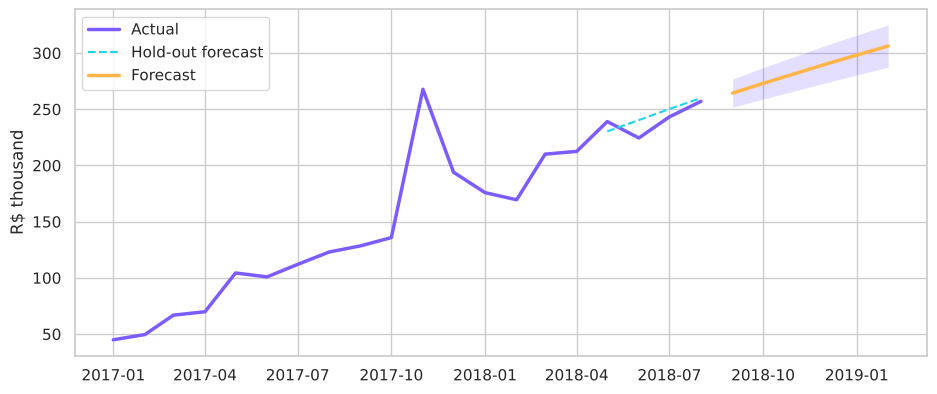

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.5))
a = fc[fc.kind == 'actual']; h = fc[fc.kind == 'holdout']; f = fc[fc.kind == 'future']
ax.plot(a.month, a.actual / 1e3, label='Actual', lw=2.5)
ax.plot(h.month, h.forecast / 1e3, '--', label='Hold-out forecast')
ax.plot(f.month, f.forecast / 1e3, label='Forecast', lw=2.5)
ax.fill_between(f.month, f.lower / 1e3, f.upper / 1e3, alpha=.2)
ax.set_ylabel('R$ thousand'); ax.legend(); plt.show()

In [3]:
print(LIMITATIONS)

Only ~20 months of history: annual seasonality is learned from a single cycle, so seasonal models are fragile. Intervals are approximate (hold-out error). Forecasts assume no new promotions, pricing or marketing changes. Use for planning ranges, not exact targets.
